# TC5061 · Exploración del conjunto Wine

**Estudiante:** Daniel Salinas Romero · **Matrícula:** A01797657

Versión exclusivamente exploratoria derivada de `TC5061_Notebook_Baseline_SalinasDaniel.ipynb`. El original de la tarea anterior se conserva sin cambios. El entrenamiento, preprocesamiento aprendido, evaluación y seguimiento se ejecutan únicamente desde `train.py`.

**Problema:** explorar 13 mediciones químicas de 178 vinos de tres variedades. Los datos están incluidos en scikit-learn y no requieren descargas.

**Ejecución:** instala `requirements-notebook.txt`, selecciona el kernel del mismo entorno y ejecuta las celdas de arriba abajo. Entorno validado: Python 3.14.7; mínimo requerido por las dependencias: Python 3.12. No se realiza ninguna partición ni ajuste de modelos en este notebook.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_wine

print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")

Python: 3.14.7 | pandas: 3.0.6 | scikit-learn: 1.9.1


## 1. Carga y descripción

Cada fila representa una muestra de vino y `target` indica la variedad (0, 1 o 2). Se mantienen los nombres y unidades tal como los distribuye la fuente, sin atribuir unidades no documentadas.

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
features = list(wine.feature_names)
print(f"Registros: {len(df)} | Variables predictoras: {len(features)}")
print("Clases:", dict(enumerate(wine.target_names)))
display(df.head())
display(df.dtypes.rename("tipo").to_frame())

Registros: 178 | Variables predictoras: 13
Clases: {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,tipo
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


## 2. Estadística y balance de clases

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


,registros
target,
0,59
1,71
2,48


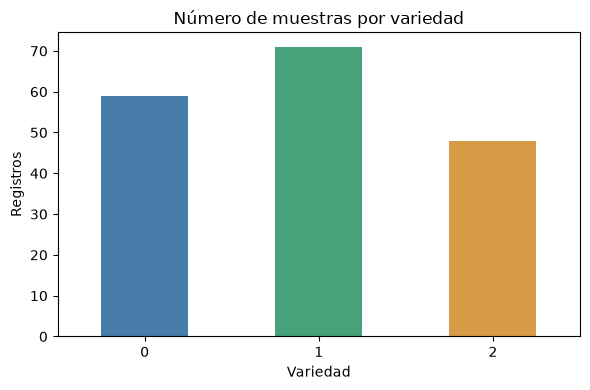

In [3]:
display(df[features].describe().T)
counts = df["target"].value_counts().sort_index()
display(counts.rename("registros").to_frame())
ax = counts.plot.bar(color=["#477da8", "#48a17b", "#d79b48"], figsize=(6, 4), rot=0)
ax.set(title="Número de muestras por variedad", xlabel="Variedad", ylabel="Registros")
plt.tight_layout()
plt.show()

## 3. Distribuciones y correlaciones

Se exploran variables con distintas escalas y la asociación lineal entre predictores. La correlación no demuestra causalidad.

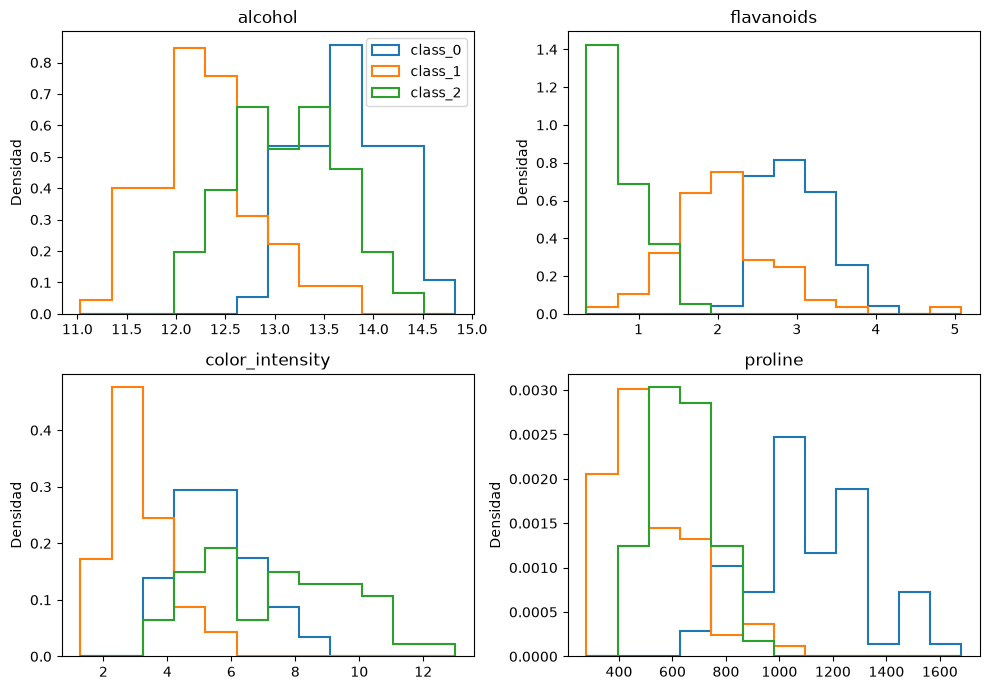

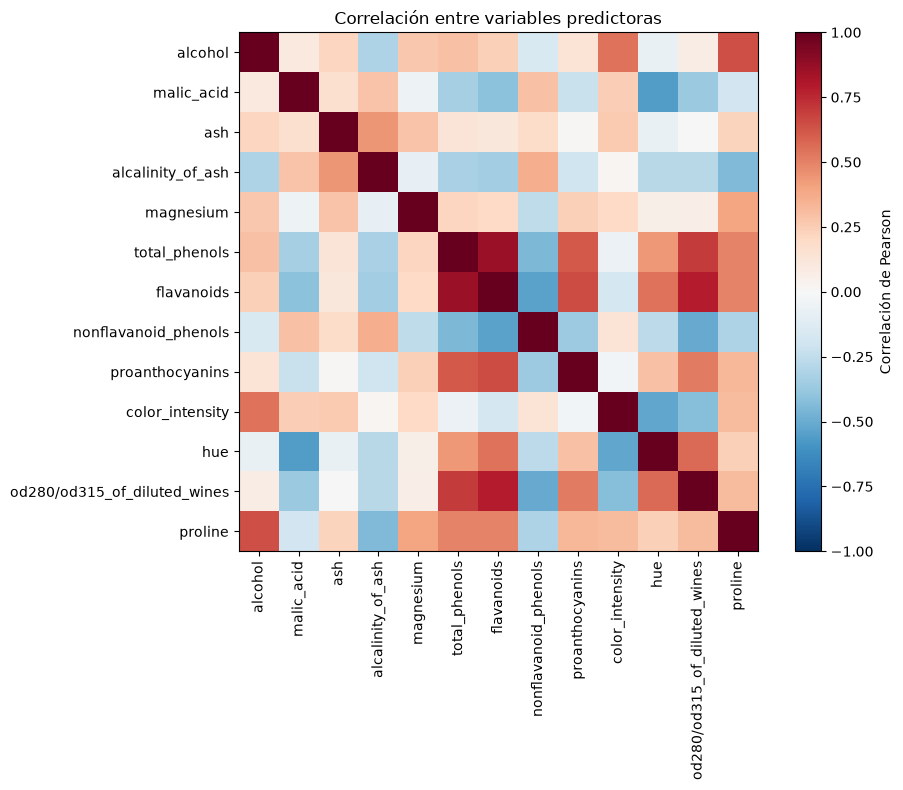

Rangos de alcohol y proline:


,alcohol,proline
min,11.03,278.0
max,14.83,1680.0


Correlación total_phenols / flavanoids: 0.865


In [4]:
columns = ["alcohol", "flavanoids", "color_intensity", "proline"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, column in zip(axes.flat, columns):
    bins = np.histogram_bin_edges(df[column], bins=12)
    for label, name in enumerate(wine.target_names):
        ax.hist(df.loc[df["target"] == label, column], bins=bins,
                histtype="step", density=True, linewidth=1.5, label=name)
    ax.set(title=column, ylabel="Densidad")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

corr = df[features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
plot = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), labels=features, rotation=90)
ax.set_yticks(range(len(features)), labels=features)
ax.set_title("Correlación entre variables predictoras")
fig.colorbar(plot, ax=ax, label="Correlación de Pearson")
plt.tight_layout()
plt.show()
print("Rangos de alcohol y proline:")
display(df[["alcohol", "proline"]].agg(["min", "max"]))
print(f"Correlación total_phenols / flavanoids: {corr.loc['total_phenols', 'flavanoids']:.3f}")

## 4. Calidad de datos y valores extremos

Se cuantifican faltantes, duplicados y valores fuera de 1.5 × IQR. Esta inspección no imputa, escala ni elimina observaciones; esas responsabilidades pertenecen a `train.py`. Un valor extremo no implica un error de medición.

,faltantes
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Filas exactamente duplicadas: 0
Registros con al menos un valor fuera del IQR: 17


,valores_fuera_IQR
alcalinity_of_ash,4
magnesium,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
flavanoids,0


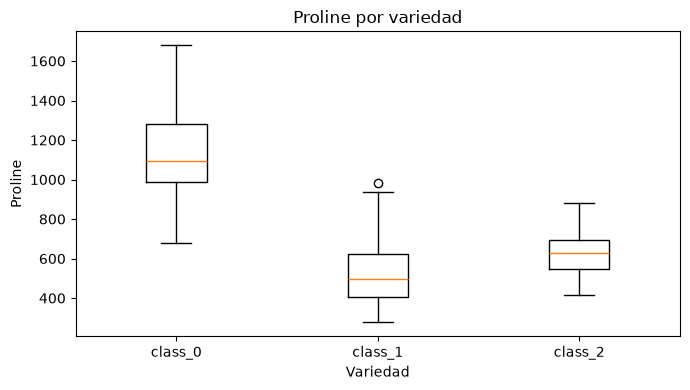

In [5]:
display(df.isna().sum().rename("faltantes").to_frame())
print("Filas exactamente duplicadas:", int(df.duplicated().sum()))
q1 = df[features].quantile(0.25)
q3 = df[features].quantile(0.75)
iqr = q3 - q1
outliers = df[features].lt(q1 - 1.5 * iqr) | df[features].gt(q3 + 1.5 * iqr)
print("Registros con al menos un valor fuera del IQR:", int(outliers.any(axis=1).sum()))
display(outliers.sum().sort_values(ascending=False).rename("valores_fuera_IQR").to_frame())
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df["target"] == label, "proline"] for label in range(3)],
           tick_labels=list(wine.target_names))
ax.set(title="Proline por variedad", xlabel="Variedad", ylabel="Proline")
plt.tight_layout()
plt.show()

## 5. Hallazgos y alcance

- Las clases tienen 59, 71 y 48 observaciones: no están perfectamente balanceadas.
- `alcohol` varía de 11.03 a 14.83 y `proline` de 278 a 1680; las escalas difieren considerablemente.
- La correlación entre `total_phenols` y `flavanoids` es aproximadamente 0.865.
- No hay faltantes ni duplicados exactos. La regla IQR identifica 17 registros con al menos un valor extremo; se conservan por falta de evidencia de error.

El script conserva la imputación por mediana y el escalado robusto del trabajo anterior, ajustados exclusivamente con entrenamiento. Aquí no se estiman métricas predictivas ni se seleccionan hiperparámetros. Este EDA sobre el conjunto completo es descriptivo y no equivale a una validación independiente; las limitaciones de la selección se documentan en `analisis_resultados.md`.

## Referencias

- [UCI: Wine](https://archive.ics.uci.edu/dataset/109/wine).
- [scikit-learn: load_wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

Para entrenar y comparar corridas, consulta el `README.md` y utiliza `train.py`.